In [1]:
import pandas as pd 
pd.set_option('display.max_columns', 500)
from tqdm import tqdm
import numpy as np
from matplotlib import pyplot as plt 
#import lightgbm as lgb
from scipy.stats import mode
from sklearn.preprocessing import LabelEncoder
from datetime import timedelta
from pandas import pivot_table

import seaborn as sns
sns.set()
%config InlineBackend.figure_format = 'svg'

### Author Sergei Bulaev , Slack name: @ser-serege ,  Fall 2018

## Part 1. Dataset and features description

###### This dataset contains the history of customer transactions for 3 months of preferential use of the banking product.

In the test file.the csv contains lines of c 518375 transactions made by the clients of the Bank. The cl_id column contains the internal client id. For each unique cl_id, you should predict whether the client will continue to use the product (target_flag). A value of 0 indicates failure and a value of 1 indicates continued use.

| Column        | Transcription                         |
|---------------|---------------------------------------|
|PERIOD         |transaction month                      |       
|cl_id          |client id                              |
|MCC            |seller category code                   |
|channel_type   |customer engagement channel            |
|currency       |currency                               |
|TRDATETIME     |transaction date/time                  |
|amount         |transaction amount                     |
|trx_category   |type of transaction POS payment through
|               |the POS terminal, C2C_OUT – transfer 
|               |(outgoing payment), C2C_IN – card      |
|               |transaction (incoming payment), DEPOSIT| 
|               |card in the ATM, WD_ATM_PARTNER – cash |
|               | withdrawals at ATMs partners
|target_flag    |will the customer continue to use the product after the grace period (1/0) (target)
|target_sum     | the amount of the transaction kind of POS for the three future months (target)

In [2]:
#raw_df = pd.read_csv('Rosbankk.csv',error_bad_lines=False)
#
#raw_df.to_csv('rosbank_train.csv')
#test = pd.read_csv('rosbank_test.csv',error_bad_lines=False)
raw_df = pd.read_csv('Rosbankk.csv',error_bad_lines=False)

In [3]:
#raw_df = pd.read_csv('rosbank_train.csv',error_bad_lines=False)
#del raw_df['Unnamed: 0']

In [4]:
raw_df.head()

,PERIOD,cl_id,MCC,channel_type,currency,TRDATETIME,amount,trx_category,target_flag,target_sum
0,01/10/2017,0,5200,NaN,810,21OCT17:00:00:00,5023.0,POS,0,0.0
1,01/10/2017,0,6011,NaN,810,12OCT17:12:24:07,20000.0,DEPOSIT,0,0.0
2,01/12/2017,0,5921,NaN,810,05DEC17:00:00:00,767.0,POS,0,0.0
3,01/10/2017,0,5411,NaN,810,21OCT17:00:00:00,2031.0,POS,0,0.0
4,01/10/2017,0,6012,NaN,810,24OCT17:13:14:24,36562.0,C2C_OUT,0,0.0


In [13]:
raw_df['cl_id'].nunique()

5000

55.3 % of taget = 1


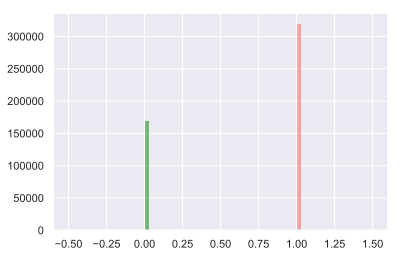

In [18]:
plt.hist(raw_df[raw_df['target_flag'] == 1]['target_flag'].dropna(), color='red', alpha=0.3, bins=30);
plt.hist(raw_df[raw_df['target_flag'] == 0]['target_flag'].dropna(), color='green', alpha=0.5, bins=30);
print(round((raw_df[raw_df['target_flag'] == 1]['cl_id'].nunique() / raw_df['cl_id'].nunique())*100,1), '% of taget = 1')

In [19]:
raw_df.info()
raw_df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 490513 entries, 0 to 490512
Data columns (total 10 columns):
PERIOD          490513 non-null object
cl_id           490513 non-null int64
MCC             490513 non-null int64
channel_type    487603 non-null object
currency        490513 non-null int64
TRDATETIME      490513 non-null object
amount          490513 non-null float64
trx_category    490513 non-null object
target_flag     490513 non-null int64
target_sum      490513 non-null float64
dtypes: float64(2), int64(4), object(4)
memory usage: 37.4+ MB


,cl_id,MCC,currency,amount,target_flag,target_sum
count,490513.000000,490513.000000,490513.000000,4.905130e+05,490513.000000,4.905130e+05
mean,4802.127361,5699.783822,810.601854,5.723594e+03,0.652588,1.627345e+05
std,2986.492835,662.933380,38.223123,7.703763e+04,0.476148,1.474097e+06
min,0.000000,742.000000,32.000000,4.000000e-02,0.000000,0.000000e+00
25%,2193.000000,5411.000000,810.000000,2.240000e+02,0.000000,0.000000e+00
50%,4576.000000,5661.000000,810.000000,6.240000e+02,1.000000,2.491009e+04
75%,7390.000000,5941.000000,810.000000,2.176000e+03,1.000000,1.516193e+05
max,10215.000000,9405.000000,986.000000,3.583500e+07,1.000000,4.606578e+07


In [20]:
print( 'Number of unique clients =',raw_df['cl_id'].nunique())
print ('At channel_type column there are ', round(100*(len(raw_df[raw_df['channel_type'].isna()]) / len(raw_df)),1), '% of empty cells')

Number of unique clients = 5000
At channel_type column there are  0.6 % of empty cells


##### Let's plot where in dimention distribution of target

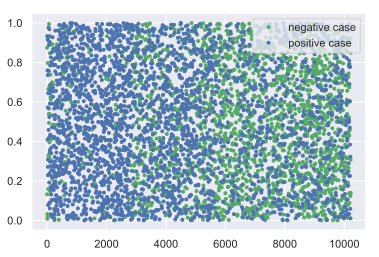

In [21]:
X = raw_df[['cl_id','target_flag']].groupby('cl_id').agg('max').reset_index()
ind = X['target_flag']==0
plt.plot(X['cl_id'][ind], np.random.rand(np.sum(ind)), 'g.', label='negative case')
ind = X['target_flag']==1
plt.plot(X['cl_id'][ind], np.random.rand(np.sum(ind)), 'b.', label='positive case')
plt.legend()

# From dataset we see, that:
MCC is not int number, it have to be categorial data(we will find descriptions in the Internet);  Currency should be also categorial data

In total there are 490513 transactions for 3 month, by made 5000 clients. In general it's about 
98 transactions by 1 client for 3 month of using card.

Time period is from 01/01/2017' to '01/12/2017'

From description we see that there are empty cells in channel_type feature. Let's fill them into 'type6'

In [27]:
raw_df.channel_type.unique()

array([nan, 'type5', 'type4', 'type2', 'type3', 'type1'], dtype=object)

In [29]:
#From description we see that there are empty cells in channel_type feature. Let's fill them into 'type6'

raw_df.channel_type.fillna('type6', inplace = True)

From description we see that PERIOD and TRDATETIME have Object type. and strange format. let's parse it and convert to datetime format

In [77]:
from datetime import datetime, date, time

raw_df['PERIOD'] = raw_df['PERIOD'].apply(pd.to_datetime)

# Creating separate cols for yr, month,...
raw_df['Year'] = raw_df.TRDATETIME.str[5:7]
raw_df['Month'] = raw_df.TRDATETIME.str[2:5]
raw_df['Date'] = raw_df.TRDATETIME.str[0:2]
raw_df['Hour'] = raw_df.TRDATETIME.str[8:10]

# Replace month with ints
raw_df.Month = raw_df.Month.replace(to_replace=['JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN','JUL','AUG',\
                                                'SEP','OCT','NOV','DEC' ], value=[1,2,3,4,5,6,7,8,9,10,11,12])

raw_df.Year = raw_df.Year.apply(pd.to_numeric)
raw_df.Date = raw_df.Date.apply(pd.to_numeric)
raw_df.Month= raw_df.Month.apply(pd.to_numeric)
raw_df.Hour = raw_df.Hour.apply(pd.to_numeric)
raw_df.Year = raw_df.Year + 2000

# making date format
def to_date(row):    
    return date(row[10], row[11], row[12])
raw_df['DateFormat'] = raw_df.apply(to_date, axis=1)

# making Quater of the Year feature 
def Quater(row):
    if row['Month']in [1, 2, 3]:
        return 1
    if row['Month']in [4, 5, 6]:
        return 2   
    if row['Month']in [7, 8, 9]:
        return 3 
    if row['Month']in [10, 11, 12]:
        return 4

# Applying features is the day is weekend and quater
raw_df['quater_of_year'] = raw_df.apply(Quater, axis = 1)
raw_df['weekend'] = raw_df['DateFormat'].astype('datetime64[ns]')
raw_df['weekend'] = ((raw_df.weekend.dt.dayofweek) // 5 ==1).astype(float)

In [26]:
raw_df.currency.unique()

array([810, 978, 504, 704, 981, 985, 840, 949,  51, 826, 214, 764, 203,
       702, 360, 756, 933, 975,  36, 191, 784, 980, 124, 398, 376, 944,
       352, 417, 156, 752, 392, 484, 634, 188, 643, 348, 356, 458, 986,
       498, 578, 208, 344,  32, 410, 788, 480, 604, 941, 144, 946, 710,
       690,  44, 170, 901, 608, 554, 462])

In [31]:
raw_df.trx_category.unique()

array(['POS', 'DEPOSIT', 'C2C_OUT', 'WD_ATM_ROS', 'BACK_TRX',
       'WD_ATM_PARTNER', 'WD_ATM_OTHER', 'C2C_IN', 'CAT', 'CASH_ADV'],
      dtype=object)

##### In python there is a library which can convert currancy. Let's convert all amounts to rubles

In [422]:
from currency_converter import CurrencyConverter

converter = CurrencyConverter(fallback_on_missing_rate=True, fallback_on_wrong_date=True)
converter_currencies = converter.currencies

def convert_to_rub(amount, currency, day):
    if currency == 'RUB':
        return amount
    else:
        if currency in converter_currencies:
            return converter.convert(amount, currency, 'RUB', date = day)
        else: amount     
        return amount
    
# also from task descripttion we know that there are cash in and cash out . 
# It that logic make the functions which convert in (+) or (-)
    
def cash_in_out(raw):
    if raw['trx_category'] == 'POS':
        return raw['amount']*(-1)
    if raw['trx_category'] == 'C2C_OUT':
        return raw['amount']*(-1)
    if raw['trx_category'] == 'WD_ATM_PARTNER':
        return raw['amount']*(-1)
    if raw['trx_category'] == 'WD_ATM_ROS':
        return raw['amount']*(-1)    
    else:
        return raw['amount']
    
raw_df['amount'] = raw_df.apply(lambda x: convert_to_rub(x['amount'], x['currency'], x['DateFormat']), axis = 1)
raw_df['cash_in_out'] = raw_df.apply(cash_in_out, axis=1)

#### Let's create a feature that discribe currnecy  Rub, Dollar ,Euro other

In [ ]:
def Is_rub(raw):
    if raw['currency'] == 810:
        return 'Rub'
    if raw['currency'] == 643:
        return 'Rub'
    if raw['currency'] ==840:
        return '$'
    if raw['currency'] == 978:
        return 'Euro'
    else: 
        return 'other'
raw_df['cur']= raw_df.apply(Is_rub, axis=1)

###### Let create a feature of start and end of perion of using the card

In [ ]:
max_date = raw_df[['cl_id', 'DateFormat']].groupby('cl_id').max().reset_index()
max_date.columns = ['cl_id', 'last_action']

raw_df = pd.merge(raw_df, max_date, how='left', on='cl_id')

##### I have a hypothesis that if client continue to usethe card actively in the end of period of  preferential use period he will continue to use card after . So let's create features for last 14 days and last 30 days before the end of period

In [ ]:
raw_df['last_action'] = pd.to_datetime(raw_df['last_action'])

raw_df['last_14_days'] = raw_df['last_action'] - timedelta(days=14)
raw_df['last_30_days'] = raw_df['last_action'] - timedelta(days=30)

raw_df['DateFormat'] = pd.to_datetime(raw_df['DateFormat'])
raw_df['last_14_days']= pd.to_datetime(raw_df['last_14_days'])
raw_df['last_30_days'] = pd.to_datetime(raw_df['last_30_days'])

def last_14_days1(row):
    if row['DateFormat']>=row['last_14_days']:
        return 1

def last_30_days1(row):
    if row['DateFormat']>=row['last_30_days']:
        return 1
    
raw_df['last_14_days'] = raw_df.apply(last_14_days1, axis=1)
raw_df['last_30_days'] = raw_df.apply(last_30_days1, axis=1)

##### The next one quation to solve is MCC (Merchnt Category Code) codes. This are codes identifies the kind of operation of client. For 

In [754]:
mcc_codes = pd.read_excel('mcc_codes1.xlsx')
mcc_codes.columns = ['MCC', 'Name' , 'Group']

raw_df = pd.merge(raw_df, mcc_codes, 'left', on=['MCC'])

In [755]:
mcc_codes.head()

,MCC,Name,Group
0,742,Ветеринарные услуги,Контрактные услуги
1,763,Сельскохозяйственные кооперативы,Контрактные услуги
2,780,Услуги садоводства и ландшафтного дизайна,Контрактные услуги
3,1520,Генеральные подрядчики – жилое и коммерческое ...,Контрактные услуги
4,1711,"Генеральные подрядчики по вентиляции, теплосна...",Контрактные услуги


##### MCC codes have current name and grouped name. We will use it for groupby functions
##### One of MCC codes means cashback from POS operations

In [759]:
def cashback(raw):
    if raw['trx_category'] == 'POS':
        return raw['amount']*0.02
raw_df['cashback'] = raw_df.apply(cashback, axis=1)

#### Finaly we have

In [70]:
raw_df.head()

,PERIOD,cl_id,MCC,channel_type,currency,TRDATETIME,amount,trx_category,target_flag,target_sum,Year,Month,Date,Hour,DateFormat,weekend,cash_in_out,quater_of_year,last_action,last_14_days,last_30_days,Name,Group,cashback,cur
0,2017-01-10,0,5200,type0,810,21OCT17:00:00:00,5023.0,POS,0,0.0,2017,10,21,0,2017-10-21,1.0,-5023.0,4,2017-12-05,0.0,0.0,Товары для дома,Розничные магазины,100.46,Rub
1,2017-01-10,0,6011,type0,810,12OCT17:12:24:07,20000.0,DEPOSIT,0,0.0,2017,10,12,12,2017-10-12,0.0,20000.0,4,2017-12-05,0.0,0.0,Финансовые учреждения – снятие наличности авто...,Поставщик услуг,0.00,Rub
2,2017-01-12,0,5921,type0,810,05DEC17:00:00:00,767.0,POS,0,0.0,2017,12,5,0,2017-12-05,0.0,-767.0,4,2017-12-05,1.0,1.0,Магазины с продажей спиртных напитков навынос,Различные магазины,15.34,Rub
3,2017-01-10,0,5411,type0,810,21OCT17:00:00:00,2031.0,POS,0,0.0,2017,10,21,0,2017-10-21,1.0,-2031.0,4,2017-12-05,0.0,0.0,"Бакалейные магазины, супермаркеты",Розничные магазины,40.62,Rub
4,2017-01-10,0,6012,type0,810,24OCT17:13:14:24,36562.0,C2C_OUT,0,0.0,2017,10,24,13,2017-10-24,0.0,-36562.0,4,2017-12-05,0.0,0.0,Финансовые учреждения – торговля и услуги,Поставщик услуг,0.00,Rub


##### All NaN's  mean that  they are equal to 0

In [69]:
raw_df = raw_df.fillna(0)

In [73]:
# Save it fo file 
#raw_df.to_csv('rosbank_train1.csv')
#raw_df = pd.read_csv('rosbank_train1.csv')

### Okay it seems that we prepare dataset for further groupby functtions. 

In [76]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 490513 entries, 0 to 490512
Data columns (total 25 columns):
PERIOD            490513 non-null object
cl_id             490513 non-null int64
MCC               490513 non-null int64
channel_type      490513 non-null object
currency          490513 non-null int64
TRDATETIME        490513 non-null object
amount            490513 non-null float64
trx_category      490513 non-null object
target_flag       490513 non-null int64
target_sum        490513 non-null float64
Year              490513 non-null int64
Month             490513 non-null int64
Date              490513 non-null int64
Hour              490513 non-null int64
DateFormat        490513 non-null object
weekend           490513 non-null float64
cash_in_out       490513 non-null float64
quater_of_year    490513 non-null int64
last_action       490513 non-null object
last_14_days      490513 non-null float64
last_30_days      490513 non-null float64
Name              490513 non-nu

In [174]:
raw_df.head(2)

,PERIOD,cl_id,MCC,channel_type,currency,TRDATETIME,amount,trx_category,target_flag,target_sum,Year,Month,Date,Hour,DateFormat,weekend,cash_in_out,quater_of_year,last_action,last_14_days,last_30_days,Name,Group,cashback,cur
0,2017-01-10,0,5200,type0,810,21OCT17:00:00:00,5023.0,POS,0,0.0,2017,10,21,0,2017-10-21,1.0,-5023.0,4,2017-12-05,0.0,0.0,Товары для дома,Розничные магазины,100.46,Rub
1,2017-01-10,0,6011,type0,810,12OCT17:12:24:07,20000.0,DEPOSIT,0,0.0,2017,10,12,12,2017-10-12,0.0,20000.0,4,2017-12-05,0.0,0.0,Финансовые учреждения – снятие наличности авто...,Поставщик услуг,0.00,Rub


##### Doing some aggregations to generate sample of unique clients. General approach is to count for categorial features and aggregate by for numerical ['max', 'min', 'mean', 'count' , 'sum']

In [173]:
def days_in_use(x):
    return (np.max(x) - np.min(x)).days

days_usage = raw_df[['cl_id','DateFormat']].groupby('cl_id').agg(days_in_use)

days_usage['target_flag'] = raw_df['target_flag']

max_date = raw_df[['cl_id', 'DateFormat']].groupby('cl_id').max()
days_usage['days_from_end_period']= (max(raw_df['DateFormat']) - max_date['DateFormat']).dt.days


num_trans_total = raw_df[['cl_id','DateFormat']].groupby('cl_id').agg('count').reset_index()
num_trans_total.columns = ['cl_id', 'num_trans_total']
num_trans_total.index=num_trans_total.cl_id
days_usage['Num_trans_total'] = num_trans_total.num_trans_total

num_trans_month = raw_df[['cl_id','Month']].groupby('cl_id').agg(['max', 'min', 'mean', 'count', 'sum']).reset_index()
#num_trans_month.columns = ['cl_id', 'num_trans_month']
num_trans_month.index=num_trans_month.cl_id
days_usage[num_trans_month.columns] = num_trans_month


balance_on_end_of_period = raw_df[['cl_id', 'cash_in_out']].groupby('cl_id').agg(['max', 'min', 'mean', 'count','sum']).reset_index()
#balance_on_end_of_period.columns=['cl_id', 'balance_on_end_of_period']
balance_on_end_of_period.index=balance_on_end_of_period.cl_id
days_usage[balance_on_end_of_period.columns] = balance_on_end_of_period

cashback = raw_df[['cl_id', 'cashback']].groupby('cl_id').sum().reset_index()
cashback.columns=['cl_id', 'cashback']
cashback.index=cashback.cl_id
days_usage['cashback'] = cashback.cashback


spent_trx_category = raw_df[['cl_id', 'trx_category' ,'amount']].groupby(['cl_id', 'trx_category']).sum().\
                                                                                        unstack().reset_index()
spent_trx_category=spent_trx_category.fillna(0)
spent_trx_category.columns = ['cl_id', 'BACK_TRX', 'C2C_IN', 'C2C_OUT', 'CASH_ADV', 'CAT', 'DEPOSIT',
       'POS', 'WD_ATM_OTHER', 'WD_ATM_PARTNER', 'WD_ATM_ROS'] 
spent_trx_category.index= spent_trx_category.cl_id

days_usage[['BACK_TRX', 'C2C_IN', 'C2C_OUT', 'CASH_ADV', 'CAT', 'DEPOSIT',
       'POS', 'WD_ATM_OTHER', 'WD_ATM_PARTNER', 'WD_ATM_ROS']] = spent_trx_category[['BACK_TRX', 'C2C_IN', 'C2C_OUT',\
                                 'CASH_ADV', 'CAT', 'DEPOSIT','POS', 'WD_ATM_OTHER', 'WD_ATM_PARTNER', 'WD_ATM_ROS']]

quntity_of_mcc = raw_df[['cl_id','MCC']].groupby(['cl_id','MCC']).apply(lambda x: x.count()).unstack().\
                                                                                        max(axis=1).reset_index()
quntity_of_mcc.columns=['cl_id', 'quntity_of_mcc']
quntity_of_mcc.index= quntity_of_mcc.cl_id
days_usage['quntity_of_mcc']=quntity_of_mcc.quntity_of_mcc




multy_currency = raw_df[['cl_id', 'currency']].groupby(['cl_id', 'currency']).first().reset_index()
multy_currency = multy_currency.groupby(['cl_id']).count()
#multy_currency.index= multy_currency.cl_id

days_usage['multy_currency']=multy_currency.currency



last_14_days=raw_df[['cl_id', 'last_14_days']].groupby(['cl_id']).agg('sum')
last_30_days=raw_df[['cl_id', 'last_30_days']].groupby(['cl_id']).agg('sum')

days_usage[last_14_days.columns]=last_14_days
days_usage[last_30_days.columns]=last_30_days




group_mcc = pivot_table(raw_df, values='cash_in_out', 
                    index=['cl_id'], columns=['Group'], aggfunc=lambda cash_in_out: len(cash_in_out.unique())).fillna(0)
group_mcc2 = pivot_table(raw_df, values='cash_in_out', 
                    index=['cl_id'], columns=['Group'], aggfunc=np.sum).fillna(0)

mcc = pd.merge(group_mcc, group_mcc2, 'left', on=days_usage.index)

mcc.index=mcc.key_0
days_usage[mcc.columns]= mcc
del days_usage['key_0']

trx_category = raw_df[['cl_id','trx_category', 'cash_in_out']].groupby(['cl_id','trx_category']).agg(['max', \
                                                                'min', 'mean', 'count', 'sum']).unstack()
days_usage[trx_category.columns]=trx_category


quater_of_year = raw_df[['cl_id', 'quater_of_year']].groupby('cl_id').agg('sum').reset_index()
#quater_of_year.columns=['cl_id', 'quater_of_year']
quater_of_year.index=quater_of_year.cl_id
days_usage[quater_of_year.columns] = quater_of_year



last_action = raw_df[['cl_id', 'last_action']].groupby('cl_id').count().reset_index()
last_action.columns=['cl_id', 'last_action']
last_action.index=last_action.cl_id
days_usage['last_action'] = last_action.last_action

cur = raw_df[['cl_id','cur', 'cash_in_out']].groupby(['cl_id','cur']).agg(['max', 'min', 'mean', 'count', 'sum'\
                                                                          ]).unstack()
#cur.index=cur.cl_id
days_usage[cur.columns]=cur

last_14_days = raw_df[['cl_id', 'last_14_days']].groupby('cl_id').agg(['max', 'min', 'mean', 'count', 'sum'\
                                                                      ]).reset_index()
#last_14_days.columns=['cl_id', 'last_14_days']
last_14_days.index=last_14_days.cl_id
days_usage[last_14_days.columns] = last_14_days

last_30_days = raw_df[['cl_id', 'last_30_days']].groupby('cl_id').agg(['max', 'min', 'mean', 'count', 'sum'\
                                                                      ]).reset_index()
#last_30_days.columns=['cl_id', 'last_30_days']
last_30_days.index=last_14_days.cl_id
days_usage[last_30_days.columns] = last_30_days

##### Another one feature could be relation between (all count of transactions)  / to (count of transactions by 14 last days and 30 last days)

In [177]:
days_usage['all_to_last14'] =  days_usage['last_14_days'] / days_usage['Num_trans_total']
days_usage['all_to_last30'] =  days_usage['last_30_days'] / days_usage['Num_trans_total']

#### We've got a dataset with 139 aggregated features

In [178]:
days_usage.head()

,DateFormat,target_flag,days_from_end_period,Num_trans_total,"(cl_id, )","(Month, max)","(Month, min)","(Month, mean)","(Month, count)","(Month, sum)","(cash_in_out, max)","(cash_in_out, min)","(cash_in_out, mean)","(cash_in_out, count)","(cash_in_out, sum)",cashback,BACK_TRX,C2C_IN,C2C_OUT,CASH_ADV,CAT,DEPOSIT,POS,WD_ATM_OTHER,WD_ATM_PARTNER,WD_ATM_ROS,quntity_of_mcc,multy_currency,last_14_days,last_30_days,0_x,"Авиалинии, авиакомпании_x",Автомобили и транспортные средства_x,Аренда автомобилей_x,Бизнес услуги_x,Государственные услуги_x,Коммунальные и кабельные услуги_x,Контрактные услуги_x,Личные услуги_x,Магазины одежды_x,Оптовые поставщики и производители_x,Отели и мотели_x,Поставщик услуг_x,Продажи по почте/телефону_x,Профессиональные услуги_x,Развлечения_x,Различные магазины_x,Ремонтные услуги_x,Розничные магазины_x,Транспорт_x,Членские организации_x,0_y,"Авиалинии, авиакомпании_y",Автомобили и транспортные средства_y,Аренда автомобилей_y,Бизнес услуги_y,Государственные услуги_y,Коммунальные и кабельные услуги_y,Контрактные услуги_y,Личные услуги_y,Магазины одежды_y,Оптовые поставщики и производители_y,Отели и мотели_y,Поставщик услуг_y,Продажи по почте/телефону_y,Профессиональные услуги_y,Развлечения_y,Различные магазины_y,Ремонтные услуги_y,Розничные магазины_y,Транспорт_y,Членские организации_y,"(cash_in_out, max, BACK_TRX)","(cash_in_out, max, C2C_IN)","(cash_in_out, max, C2C_OUT)","(cash_in_out, max, CASH_ADV)","(cash_in_out, max, CAT)","(cash_in_out, max, DEPOSIT)","(cash_in_out, max, POS)","(cash_in_out, max, WD_ATM_OTHER)","(cash_in_out, max, WD_ATM_PARTNER)","(cash_in_out, max, WD_ATM_ROS)","(cash_in_out, min, BACK_TRX)","(cash_in_out, min, C2C_IN)","(cash_in_out, min, C2C_OUT)","(cash_in_out, min, CASH_ADV)","(cash_in_out, min, CAT)","(cash_in_out, min, DEPOSIT)","(cash_in_out, min, POS)","(cash_in_out, min, WD_ATM_OTHER)","(cash_in_out, min, WD_ATM_PARTNER)","(cash_in_out, min, WD_ATM_ROS)","(cash_in_out, mean, BACK_TRX)","(cash_in_out, mean, C2C_IN)","(cash_in_out, mean, C2C_OUT)","(cash_in_out, mean, CASH_ADV)","(cash_in_out, mean, CAT)","(cash_in_out, mean, DEPOSIT)","(cash_in_out, mean, POS)","(cash_in_out, mean, WD_ATM_OTHER)","(cash_in_out, mean, WD_ATM_PARTNER)","(cash_in_out, mean, WD_ATM_ROS)","(cash_in_out, count, BACK_TRX)","(cash_in_out, count, C2C_IN)","(cash_in_out, count, C2C_OUT)","(cash_in_out, count, CASH_ADV)","(cash_in_out, count, CAT)","(cash_in_out, count, DEPOSIT)","(cash_in_out, count, POS)","(cash_in_out, count, WD_ATM_OTHER)","(cash_in_out, count, WD_ATM_PARTNER)","(cash_in_out, count, WD_ATM_ROS)","(cash_in_out, sum, BACK_TRX)","(cash_in_out, sum, C2C_IN)","(cash_in_out, sum, C2C_OUT)","(cash_in_out, sum, CASH_ADV)","(cash_in_out, sum, CAT)","(cash_in_out, sum, DEPOSIT)","(cash_in_out, sum, POS)","(cash_in_out, sum, WD_ATM_OTHER)","(cash_in_out, sum, WD_ATM_PARTNER)","(cash_in_out, sum, WD_ATM_ROS)",cl_id,quater_of_year,last_action,"(cash_in_out, max, $)","(cash_in_out, max, Euro)","(cash_in_out, max, Rub)","(cash_in_out, max, other)","(cash_in_out, min, $)","(cash_in_out, min, Euro)","(cash_in_out, min, Rub)","(cash_in_out, min, other)","(cash_in_out, mean, $)","(cash_in_out, mean, Euro)","(cash_in_out, mean, Rub)","(cash_in_out, mean, other)","(cash_in_out, count, $)","(cash_in_out, count, Euro)","(cash_in_out, count, Rub)","(cash_in_out, count, other)","(cash_in_out, sum, $)","(cash_in_out, sum, Euro)","(cash_in_out, sum, Rub)","(cash_in_out, sum, other)",all_to_last14,all_to_last30
cl_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,54,0,118,5,0,12,10,10.400000,5,52,20000.0,-36562.00,-4876.600000,5,-24383.00,156.4200,0.0,0.0,36562.00,0.0,0.00,20000.0,7821.00,0.0,0.0,0.0,1.0,1,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,-16562.00,0.0,0.0,0.00,-767.00,0.0,-7054.00,0.00,0.0,NaN,NaN,-365

In [179]:
days_usage.describe()

,DateFormat,target_flag,days_from_end_period,Num_trans_total,"(cl_id, )","(Month, max)","(Month, min)","(Month, mean)","(Month, count)","(Month, sum)","(cash_in_out, max)","(cash_in_out, min)","(cash_in_out, mean)","(cash_in_out, count)","(cash_in_out, sum)",cashback,BACK_TRX,C2C_IN,C2C_OUT,CASH_ADV,CAT,DEPOSIT,POS,WD_ATM_OTHER,WD_ATM_PARTNER,WD_ATM_ROS,quntity_of_mcc,multy_currency,last_14_days,last_30_days,0_x,"Авиалинии, авиакомпании_x",Автомобили и транспортные средства_x,Аренда автомобилей_x,Бизнес услуги_x,Государственные услуги_x,Коммунальные и кабельные услуги_x,Контрактные услуги_x,Личные услуги_x,Магазины одежды_x,Оптовые поставщики и производители_x,Отели и мотели_x,Поставщик услуг_x,Продажи по почте/телефону_x,Профессиональные услуги_x,Развлечения_x,Различные магазины_x,Ремонтные услуги_x,Розничные магазины_x,Транспорт_x,Членские организации_x,0_y,"Авиалинии, авиакомпании_y",Автомобили и транспортные средства_y,Аренда автомобилей_y,Бизнес услуги_y,Государственные услуги_y,Коммунальные и кабельные услуги_y,Контрактные услуги_y,Личные услуги_y,Магазины одежды_y,Оптовые поставщики и производители_y,Отели и мотели_y,Поставщик услуг_y,Продажи по почте/телефону_y,Профессиональные услуги_y,Развлечения_y,Различные магазины_y,Ремонтные услуги_y,Розничные магазины_y,Транспорт_y,Членские организации_y,"(cash_in_out, max, BACK_TRX)","(cash_in_out, max, C2C_IN)","(cash_in_out, max, C2C_OUT)","(cash_in_out, max, CASH_ADV)","(cash_in_out, max, CAT)","(cash_in_out, max, DEPOSIT)","(cash_in_out, max, POS)","(cash_in_out, max, WD_ATM_OTHER)","(cash_in_out, max, WD_ATM_PARTNER)","(cash_in_out, max, WD_ATM_ROS)","(cash_in_out, min, BACK_TRX)","(cash_in_out, min, C2C_IN)","(cash_in_out, min, C2C_OUT)","(cash_in_out, min, CASH_ADV)","(cash_in_out, min, CAT)","(cash_in_out, min, DEPOSIT)","(cash_in_out, min, POS)","(cash_in_out, min, WD_ATM_OTHER)","(cash_in_out, min, WD_ATM_PARTNER)","(cash_in_out, min, WD_ATM_ROS)","(cash_in_out, mean, BACK_TRX)","(cash_in_out, mean, C2C_IN)","(cash_in_out, mean, C2C_OUT)","(cash_in_out, mean, CASH_ADV)","(cash_in_out, mean, CAT)","(cash_in_out, mean, DEPOSIT)","(cash_in_out, mean, POS)","(cash_in_out, mean, WD_ATM_OTHER)","(cash_in_out, mean, WD_ATM_PARTNER)","(cash_in_out, mean, WD_ATM_ROS)","(cash_in_out, count, BACK_TRX)","(cash_in_out, count, C2C_IN)","(cash_in_out, count, C2C_OUT)","(cash_in_out, count, CASH_ADV)","(cash_in_out, count, CAT)","(cash_in_out, count, DEPOSIT)","(cash_in_out, count, POS)","(cash_in_out, count, WD_ATM_OTHER)","(cash_in_out, count, WD_ATM_PARTNER)","(cash_in_out, count, WD_ATM_ROS)","(cash_in_out, sum, BACK_TRX)","(cash_in_out, sum, C2C_IN)","(cash_in_out, sum, C2C_OUT)","(cash_in_out, sum, CASH_ADV)","(cash_in_out, sum, CAT)","(cash_in_out, sum, DEPOSIT)","(cash_in_out, sum, POS)","(cash_in_out, sum, WD_ATM_OTHER)","(cash_in_out, sum, WD_ATM_PARTNER)","(cash_in_out, sum, WD_ATM_ROS)",cl_id,quater_of_year,last_action,"(cash_in_out, max, $)","(cash_in_out, max, Euro)","(cash_in_out, max, Rub)","(cash_in_out, max, other)","(cash_in_out, min, $)","(cash_in_out, min, Euro)","(cash_in_out, min, Rub)","(cash_in_out, min, other)","(cash_in_out, mean, $)","(cash_in_out, mean, Euro)","(cash_in_out, mean, Rub)","(cash_in_out, mean, other)","(cash_in_out, count, $)","(cash_in_out, count, Euro)","(cash_in_out, count, Rub)","(cash_in_out, count, other)","(cash_in_out, sum, $)","(cash_in_out, sum, Euro)","(cash_in_out, sum, Rub)","(cash_in_out, sum, other)",all_to_last14,all_to_last30
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03,5.000000e+03,5000.000000,5000.000000,5.000000e+03,5000.000000,5.000000e+03,5.000000e+03,5.000000e+03,5000.000000,5.000000e+03,5.000000e+03,5.000000e+03,5.000000e+03,5.000000e+03,5.000000e+03,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000

##### For sure there are a lot of NaN because of aggregations. So, if Nan, fill it by 0

In [180]:
days_usage=days_usage.fillna(0)

In [ ]:
days_usage.

In [194]:
days_usage.head()

,DateFormat,target_flag,days_from_end_period,Num_trans_total,"(cl_id, )","(Month, max)","(Month, min)","(Month, mean)","(Month, count)","(Month, sum)","(cash_in_out, max)","(cash_in_out, min)","(cash_in_out, mean)","(cash_in_out, count)","(cash_in_out, sum)",cashback,BACK_TRX,C2C_IN,C2C_OUT,CASH_ADV,CAT,DEPOSIT,POS,WD_ATM_OTHER,WD_ATM_PARTNER,WD_ATM_ROS,quntity_of_mcc,multy_currency,last_14_days,last_30_days,0_x,"Авиалинии, авиакомпании_x",Автомобили и транспортные средства_x,Аренда автомобилей_x,Бизнес услуги_x,Государственные услуги_x,Коммунальные и кабельные услуги_x,Контрактные услуги_x,Личные услуги_x,Магазины одежды_x,Оптовые поставщики и производители_x,Отели и мотели_x,Поставщик услуг_x,Продажи по почте/телефону_x,Профессиональные услуги_x,Развлечения_x,Различные магазины_x,Ремонтные услуги_x,Розничные магазины_x,Транспорт_x,Членские организации_x,0_y,"Авиалинии, авиакомпании_y",Автомобили и транспортные средства_y,Аренда автомобилей_y,Бизнес услуги_y,Государственные услуги_y,Коммунальные и кабельные услуги_y,Контрактные услуги_y,Личные услуги_y,Магазины одежды_y,Оптовые поставщики и производители_y,Отели и мотели_y,Поставщик услуг_y,Продажи по почте/телефону_y,Профессиональные услуги_y,Развлечения_y,Различные магазины_y,Ремонтные услуги_y,Розничные магазины_y,Транспорт_y,Членские организации_y,"(cash_in_out, max, BACK_TRX)","(cash_in_out, max, C2C_IN)","(cash_in_out, max, C2C_OUT)","(cash_in_out, max, CASH_ADV)","(cash_in_out, max, CAT)","(cash_in_out, max, DEPOSIT)","(cash_in_out, max, POS)","(cash_in_out, max, WD_ATM_OTHER)","(cash_in_out, max, WD_ATM_PARTNER)","(cash_in_out, max, WD_ATM_ROS)","(cash_in_out, min, BACK_TRX)","(cash_in_out, min, C2C_IN)","(cash_in_out, min, C2C_OUT)","(cash_in_out, min, CASH_ADV)","(cash_in_out, min, CAT)","(cash_in_out, min, DEPOSIT)","(cash_in_out, min, POS)","(cash_in_out, min, WD_ATM_OTHER)","(cash_in_out, min, WD_ATM_PARTNER)","(cash_in_out, min, WD_ATM_ROS)","(cash_in_out, mean, BACK_TRX)","(cash_in_out, mean, C2C_IN)","(cash_in_out, mean, C2C_OUT)","(cash_in_out, mean, CASH_ADV)","(cash_in_out, mean, CAT)","(cash_in_out, mean, DEPOSIT)","(cash_in_out, mean, POS)","(cash_in_out, mean, WD_ATM_OTHER)","(cash_in_out, mean, WD_ATM_PARTNER)","(cash_in_out, mean, WD_ATM_ROS)","(cash_in_out, count, BACK_TRX)","(cash_in_out, count, C2C_IN)","(cash_in_out, count, C2C_OUT)","(cash_in_out, count, CASH_ADV)","(cash_in_out, count, CAT)","(cash_in_out, count, DEPOSIT)","(cash_in_out, count, POS)","(cash_in_out, count, WD_ATM_OTHER)","(cash_in_out, count, WD_ATM_PARTNER)","(cash_in_out, count, WD_ATM_ROS)","(cash_in_out, sum, BACK_TRX)","(cash_in_out, sum, C2C_IN)","(cash_in_out, sum, C2C_OUT)","(cash_in_out, sum, CASH_ADV)","(cash_in_out, sum, CAT)","(cash_in_out, sum, DEPOSIT)","(cash_in_out, sum, POS)","(cash_in_out, sum, WD_ATM_OTHER)","(cash_in_out, sum, WD_ATM_PARTNER)","(cash_in_out, sum, WD_ATM_ROS)",cl_id,quater_of_year,last_action,"(cash_in_out, max, $)","(cash_in_out, max, Euro)","(cash_in_out, max, Rub)","(cash_in_out, max, other)","(cash_in_out, min, $)","(cash_in_out, min, Euro)","(cash_in_out, min, Rub)","(cash_in_out, min, other)","(cash_in_out, mean, $)","(cash_in_out, mean, Euro)","(cash_in_out, mean, Rub)","(cash_in_out, mean, other)","(cash_in_out, count, $)","(cash_in_out, count, Euro)","(cash_in_out, count, Rub)","(cash_in_out, count, other)","(cash_in_out, sum, $)","(cash_in_out, sum, Euro)","(cash_in_out, sum, Rub)","(cash_in_out, sum, other)",all_to_last14,all_to_last30
cl_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,54,0,118,5,0,12,10,10.400000,5,52,20000.0,-36562.00,-4876.600000,5,-24383.00,156.4200,0.0,0.0,36562.00,0.0,0.00,20000.0,7821.00,0.0,0.0,0.0,1.0,1,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,-16562.00,0.0,0.0,0.00,-767.00,0.0,-7054.00,0.00,0.0,0.0,0.0,-365

In [196]:
days_usage.to_csv('days_us.csv')

In [ ]:
Plotting visual info. 

In [183]:
sns.heatmap(days_usage.corr())

#### From the graph we see that there are a lot of correletad features. Let's find them and drop

In [191]:
# чтобы убрать все кореллирующие признакие
def drop_corr_col(df_corr):
    upper = df_corr.where(np.triu(np.ones(df_corr.shape),
                          k=1).astype(np.bool))
    to_drop = [column for column in upper.columns if any(upper[column] > 0.9)]
    return(to_drop)

In [198]:
corr=days_usage.corr().abs()
drop_col=drop_corr_col(corr)
print('We found and drop',len(drop_col), 'correlated features with the coefficient more then 0.9')


We found and drop 38 correlated features with the coefficient more then 0.9


In [225]:
#Let's make PCA with 2 components from all of them and then add this two components into dataset , others drop
from sklearn.decomposition import PCA
pca = PCA(n_components=2).fit_transform(days_usage[drop_col])

pca_df = pd.DataFrame(pca, columns=['pca1', 'pca2'])
pca_df.index=days_usage.index

days=days_usage.drop(drop_col, axis=1)
days[pca_df.columns]= pca_df

In [224]:
days.head()

,DateFormat,target_flag,days_from_end_period,Num_trans_total,"(cl_id, )","(Month, max)","(Month, min)","(Month, mean)","(Month, sum)","(cash_in_out, max)","(cash_in_out, min)","(cash_in_out, mean)","(cash_in_out, sum)",BACK_TRX,C2C_IN,C2C_OUT,CASH_ADV,CAT,DEPOSIT,WD_ATM_OTHER,WD_ATM_PARTNER,WD_ATM_ROS,quntity_of_mcc,multy_currency,last_14_days,0_x,"Авиалинии, авиакомпании_x",Автомобили и транспортные средства_x,Аренда автомобилей_x,Бизнес услуги_x,Государственные услуги_x,Коммунальные и кабельные услуги_x,Контрактные услуги_x,Личные услуги_x,Магазины одежды_x,Оптовые поставщики и производители_x,Отели и мотели_x,Поставщик услуг_x,Продажи по почте/телефону_x,Профессиональные услуги_x,Развлечения_x,Различные магазины_x,Ремонтные услуги_x,Розничные магазины_x,Транспорт_x,Членские организации_x,"Авиалинии, авиакомпании_y",Автомобили и транспортные средства_y,Аренда автомобилей_y,Бизнес услуги_y,Государственные услуги_y,Коммунальные и кабельные услуги_y,Контрактные услуги_y,Личные услуги_y,Магазины одежды_y,Оптовые поставщики и производители_y,Поставщик услуг_y,Продажи по почте/телефону_y,Профессиональные услуги_y,Развлечения_y,Различные магазины_y,Ремонтные услуги_y,Розничные магазины_y,"(cash_in_out, max, BACK_TRX)","(cash_in_out, max, C2C_IN)","(cash_in_out, max, C2C_OUT)","(cash_in_out, max, DEPOSIT)","(cash_in_out, max, POS)","(cash_in_out, max, WD_ATM_OTHER)","(cash_in_out, max, WD_ATM_PARTNER)","(cash_in_out, max, WD_ATM_ROS)","(cash_in_out, min, C2C_IN)","(cash_in_out, min, C2C_OUT)","(cash_in_out, min, CASH_ADV)","(cash_in_out, min, CAT)","(cash_in_out, min, DEPOSIT)","(cash_in_out, min, WD_ATM_OTHER)","(cash_in_out, min, WD_ATM_PARTNER)","(cash_in_out, min, WD_ATM_ROS)","(cash_in_out, mean, C2C_IN)","(cash_in_out, mean, C2C_OUT)","(cash_in_out, mean, DEPOSIT)","(cash_in_out, mean, POS)","(cash_in_out, mean, WD_ATM_ROS)","(cash_in_out, count, BACK_TRX)","(cash_in_out, count, C2C_IN)","(cash_in_out, count, C2C_OUT)","(cash_in_out, count, CASH_ADV)","(cash_in_out, count, CAT)","(cash_in_out, count, DEPOSIT)","(cash_in_out, count, WD_ATM_OTHER)","(cash_in_out, count, WD_ATM_PARTNER)","(cash_in_out, count, WD_ATM_ROS)","(cash_in_out, max, $)","(cash_in_out, max, Euro)","(cash_in_out, max, Rub)","(cash_in_out, max, other)","(cash_in_out, min, $)","(cash_in_out, min, Euro)","(cash_in_out, min, Rub)","(cash_in_out, mean, Euro)","(cash_in_out, count, $)","(cash_in_out, count, Euro)","(cash_in_out, count, other)","(cash_in_out, sum, $)","(cash_in_out, sum, Euro)","(cash_in_out, sum, Rub)",all_to_last14,all_to_last30,pca1,pca2
cl_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,54,0,118,5,0,12,10,10.400000,52,20000.0,-36562.00,-4876.600000,-24383.00,0.0,0.0,36562.00,0.0,0.00,20000.0,0.0,0.0,0.0,1.0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,-16562.00,0.0,0.0,0.00,-767.00,0.0,-7054.00,0.0,0.0,-36562.0,20000.0,-767.0,0.0,0.0,0.0,0.0,-36562.0,0.0,0.0,20000.0,0.0,0.0,0.0,0.000000,-36562.000000,20000.0,-2607.000000,0.000000,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,20000.0,0.0,0.0,0.00,-36562.00,0.000000,0.0,0.0,0.0,0.0,0.00,-24383.00,0.200000,0.200000,-239461.952651,-114818.223301
1,92,0,165,104,1,10,7,8.951923,931,50000.0,-60000.00,-745.942692,-77578.04,0.0,0.0,0.00,0.0,0.00,95000.0,0.0,0.0,50000.0,41.0,2,15.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,5.0,0.0,0.0,4.0,0.0,0.0,6.0,57.0,0.0,14.0,2.0,0.0,0.0,0.00,0.0,-30.0,-210.0,0.0,0.0,0.0,-7631.98,0.0,44988.00,0.0,0.0,-8628.02,-90868.78,0.0,-15146.16,0.0,0.0,0.0,50000.0,-3.0,0.0,0.0,-50000.0,0.0,0.0,0.0,0.0,45000.0,0.0,0.0,-50000.0,0.000000,0.000000,47500.0,-1213.643960,-50000.000000,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,1.0,0.0,-3.0,50000.0,0.0,0.0,-83.90,-60000.00,-26.026765,0.0,34.0,0.0,0.0,-884.91,-76693.13,0.144231,0.586538,-108185.895610,-46473.704971
5,92,0,288,142,5,6,3,4.661972,662,40000.0,-56164.05,-1742.176972,-247389.13,13990.0,0.0

In [227]:
days.to_csv('days.csv')

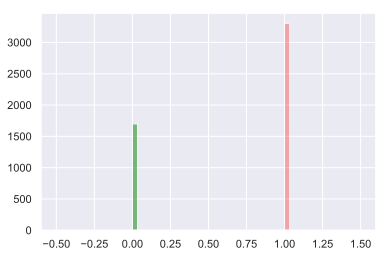

In [226]:
plt.hist(days[days['target_flag'] == 1]['target_flag'].dropna(), color='red', alpha=0.3, bins=30);
plt.hist(days[days['target_flag'] == 0]['target_flag'].dropna(), color='green', alpha=0.5, bins=30);

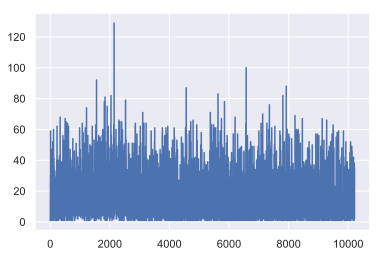

In [240]:
plt.plot(days['last_14_days'])

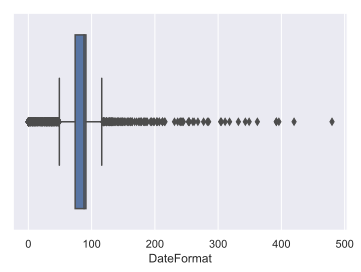

In [238]:
sns.boxplot(x='DateFormat', data=days);

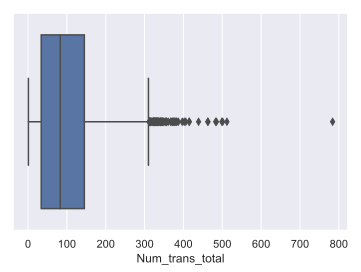

In [234]:
sns.boxplot(x='Num_trans_total', data=days);

In [400]:
sns.pairplot(days_usage[['DateFormat','days_from_end_period',
                         'multy_currency', 'quntity_of_mcc'  ] ])

### Okay, we prepared Dataset , saw on the distribution of some features. Let's choose metrics to evaluate quality of future models.
##### We have task of binary classification, so we will see on metrics ROCAUC.  Also, we have disbalance of target classes, but difference is not too big. So Accuracy and precision are good too. 

In [249]:
from sklearn.metrics import roc_auc_score, roc_curve

In [273]:
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, confusion_matrix, auc
from sklearn.model_selection import KFold, StratifiedKFold

def calc_auc(y_test2, y_pred, plot_label='', prin=True):
    fpr, tpr, _ = roc_curve(y_test2, y_pred)
    auc_val = auc(fpr, tpr)
    if prin:
        print('ROC AUC: {0:.4f}'.format(auc_val))
    if plot_label:
        plt.plot(fpr, tpr, label=plot_label)
        plt.xlabel('FPR')
        plt.ylabel('TPR')
    return auc_val

### Also make a funcion to plot confusion matrix

In [250]:
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

font = {'size' : 15}

plt.rc('font', **font)

#### We are ready to build models. 

To do it we will make Train_test_split. Because we have disbalanced classes and less number of user is oldest one, we will shake them by stratified shaffle split. 

In [267]:
X = days.copy()
y = days.target_flag
X = X.reset_index()
X.drop([('cl_id', '')], axis=1)
del X['target_flag']
del X[('cl_id', '')]

In [268]:
X.head()

,cl_id,DateFormat,days_from_end_period,Num_trans_total,"(Month, max)","(Month, min)","(Month, mean)","(Month, sum)","(cash_in_out, max)","(cash_in_out, min)","(cash_in_out, mean)","(cash_in_out, sum)",BACK_TRX,C2C_IN,C2C_OUT,CASH_ADV,CAT,DEPOSIT,WD_ATM_OTHER,WD_ATM_PARTNER,WD_ATM_ROS,quntity_of_mcc,multy_currency,last_14_days,0_x,"Авиалинии, авиакомпании_x",Автомобили и транспортные средства_x,Аренда автомобилей_x,Бизнес услуги_x,Государственные услуги_x,Коммунальные и кабельные услуги_x,Контрактные услуги_x,Личные услуги_x,Магазины одежды_x,Оптовые поставщики и производители_x,Отели и мотели_x,Поставщик услуг_x,Продажи по почте/телефону_x,Профессиональные услуги_x,Развлечения_x,Различные магазины_x,Ремонтные услуги_x,Розничные магазины_x,Транспорт_x,Членские организации_x,"Авиалинии, авиакомпании_y",Автомобили и транспортные средства_y,Аренда автомобилей_y,Бизнес услуги_y,Государственные услуги_y,Коммунальные и кабельные услуги_y,Контрактные услуги_y,Личные услуги_y,Магазины одежды_y,Оптовые поставщики и производители_y,Поставщик услуг_y,Продажи по почте/телефону_y,Профессиональные услуги_y,Развлечения_y,Различные магазины_y,Ремонтные услуги_y,Розничные магазины_y,"(cash_in_out, max, BACK_TRX)","(cash_in_out, max, C2C_IN)","(cash_in_out, max, C2C_OUT)","(cash_in_out, max, DEPOSIT)","(cash_in_out, max, POS)","(cash_in_out, max, WD_ATM_OTHER)","(cash_in_out, max, WD_ATM_PARTNER)","(cash_in_out, max, WD_ATM_ROS)","(cash_in_out, min, C2C_IN)","(cash_in_out, min, C2C_OUT)","(cash_in_out, min, CASH_ADV)","(cash_in_out, min, CAT)","(cash_in_out, min, DEPOSIT)","(cash_in_out, min, WD_ATM_OTHER)","(cash_in_out, min, WD_ATM_PARTNER)","(cash_in_out, min, WD_ATM_ROS)","(cash_in_out, mean, C2C_IN)","(cash_in_out, mean, C2C_OUT)","(cash_in_out, mean, DEPOSIT)","(cash_in_out, mean, POS)","(cash_in_out, mean, WD_ATM_ROS)","(cash_in_out, count, BACK_TRX)","(cash_in_out, count, C2C_IN)","(cash_in_out, count, C2C_OUT)","(cash_in_out, count, CASH_ADV)","(cash_in_out, count, CAT)","(cash_in_out, count, DEPOSIT)","(cash_in_out, count, WD_ATM_OTHER)","(cash_in_out, count, WD_ATM_PARTNER)","(cash_in_out, count, WD_ATM_ROS)","(cash_in_out, max, $)","(cash_in_out, max, Euro)","(cash_in_out, max, Rub)","(cash_in_out, max, other)","(cash_in_out, min, $)","(cash_in_out, min, Euro)","(cash_in_out, min, Rub)","(cash_in_out, mean, Euro)","(cash_in_out, count, $)","(cash_in_out, count, Euro)","(cash_in_out, count, other)","(cash_in_out, sum, $)","(cash_in_out, sum, Euro)","(cash_in_out, sum, Rub)",all_to_last14,all_to_last30,pca1,pca2
0,0,54,118,5,12,10,10.400000,52,20000.0,-36562.00,-4876.600000,-24383.00,0.0,0.0,36562.00,0.0,0.00,20000.0,0.0,0.0,0.0,1.0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,-16562.00,0.0,0.0,0.00,-767.00,0.0,-7054.00,0.0,0.0,-36562.0,20000.0,-767.0,0.0,0.0,0.0,0.0,-36562.0,0.0,0.0,20000.0,0.0,0.0,0.0,0.000000,-36562.000000,20000.0,-2607.000000,0.000000,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,20000.0,0.0,0.0,0.00,-36562.00,0.000000,0.0,0.0,0.0,0.0,0.00,-24383.00,0.200000,0.200000,-239461.952651,-114818.223302
1,1,92,165,104,10,7,8.951923,931,50000.0,-60000.00,-745.942692,-77578.04,0.0,0.0,0.00,0.0,0.00,95000.0,0.0,0.0,50000.0,41.0,2,15.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,5.0,0.0,0.0,4.0,0.0,0.0,6.0,57.0,0.0,14.0,2.0,0.0,0.0,0.00,0.0,-30.0,-210.0,0.0,0.0,0.0,-7631.98,0.0,44988.00,0.0,0.0,-8628.02,-90868.78,0.0,-15146.16,0.0,0.0,0.0,50000.0,-3.0,0.0,0.0,-50000.0,0.0,0.0,0.0,0.0,45000.0,0.0,0.0,-50000.0,0.000000,0.000000,47500.0,-1213.643960,-50000.000000,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,1.0,0.0,-3.0,50000.0,0.0,0.0,-83.90,-60000.00,-26.026765,0.0,34.0,0.0,0.0,-884.91,-76693.13,0.144231,0.586538,-108185.895610,-46473.704971
2,5,92,288,142,6,3,4.661972,662,40000.0,-56164.05,-1742.176972,-247389.13,13990.0,0.0,33878.38,0.0,0.00,130000.0,5500.0,6000.0,66500.0,31.0,3,30.0,0.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,2.0,18.0,0.0,2.0,14.0,0.0,1.0,5.0,23.0,0.0,42.0

In [369]:
from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(n_splits=2, test_size=0.3, random_state=17)

for train_index, test_index in splitter.split(X, y):
    X_train = X.iloc[train_index]
    X_test = X.iloc[test_index]
    
    y_train = y.iloc[train_index]
    y_test = y.iloc[test_index]

In [278]:
import xgboost
from sklearn.metrics import roc_auc_score, roc_curve
xgb = xgboost.XGBClassifier(learning_rate=0.1, max_depth=5, n_jobs=-1)
xgb.fit(X_train, y_train)
y_train_predict = xgb.predict_proba(X_train)[:, 1]
y_test_predict = xgb.predict_proba(X_test)[:, 1]
roc_auc_train = np.round(roc_auc_score(y_train, y_train_predict), 2)
roc_auc_test = np.round(roc_auc_score(y_test, y_test_predict), 2)
print("Train: ", roc_auc_train)
print("Test: ", roc_auc_test)

Train:  1.0
Test:  0.98


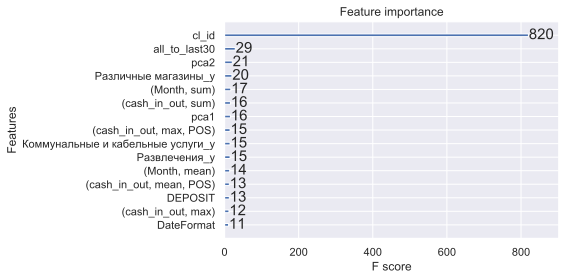

In [279]:
from xgboost import plot_importance
plot_importance(xgb, max_num_features = 15)

## We see that cl_id is data leak. Drop it.

In [294]:
del X_train['cl_id']
del X_test['cl_id']

In [300]:
import xgboost
from sklearn.metrics import roc_auc_score, roc_curve
xgb = xgboost.XGBClassifier( n_jobs=-1)
xgb.fit(X_train, y_train)
y_train_predict = xgb.predict_proba(X_train)[:, 1]
y_test_predict = xgb.predict_proba(X_test)[:, 1]
roc_auc_train = np.round(roc_auc_score(y_train, y_train_predict), 2)
roc_auc_test = np.round(roc_auc_score(y_test, y_test_predict), 2)
print("Train: ", roc_auc_train)
print("Test: ", roc_auc_test)

Train:  0.82
Test:  0.59


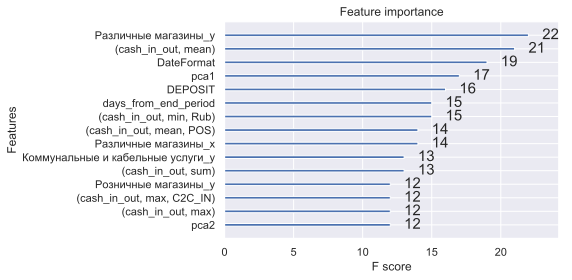

In [301]:
from xgboost import plot_importance
plot_importance(xgb, max_num_features = 15)

Bad results. Lets buid simple Logistic regression

0.64
0.57
Train:
ROC AUC: 0.6408
Test:
ROC AUC: 0.5678


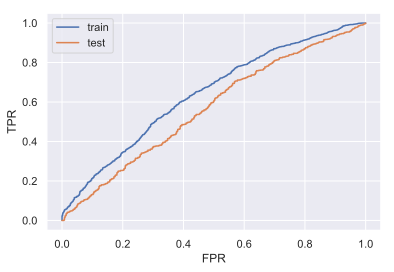

In [389]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression, LogisticRegression

scaler= StandardScaler()
X_scaled_train = scaler.fit_transform(X_train)
X_scaled_test = scaler.transform(X_test)

lr=LogisticRegression()
lr.fit(X_scaled_train,y_train)
y_pred_train= lr.predict_proba(X_scaled_train)
y_pred_test= lr.predict_proba(X_scaled_test)

#.fit(x_train1_l1,y_train).score(x_train1_l1,y_train)
#print(score)
print(np.round(roc_auc_score(y_train, y_pred_train[:,1]), 2))
print(np.round(roc_auc_score(y_test, y_pred_test[:,1]), 2))

y_pred_rf_test1 = lr.predict_proba(X_scaled_test)[:, 1]
y_pred_rf_train1 = lr.predict_proba(X_scaled_train)[:, 1]

print('Train:')
calc_auc(y_train, y_pred_rf_train1, 'train')
print('Test:')
calc_auc(y_test, y_pred_rf_test1, 'test')
plt.legend();

## A little bit better then random

In [303]:
from catboost import CatBoost, CatBoostClassifier

model = CatBoostClassifier( )

model.fit(
    X_train, y_train,
    #cat_features=categorical_features_indices,
    eval_set=(X_test, y_test),
    logging_level='Silent',
    plot=True
);

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

## Over fitting and the best result so far

Train:
ROC AUC: 0.7879
Test:
ROC AUC: 0.6003


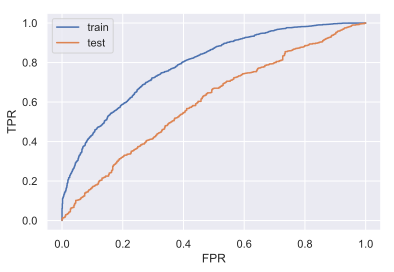

In [305]:
y_pred_rf_test1 = model.predict_proba(X_test)[:, 1]
y_pred_rf_train1 = model.predict_proba(X_train)[:, 1]

print('Train:')
calc_auc(y_train, y_pred_rf_train1, 'train')
print('Test:')
calc_auc(y_test, y_pred_rf_test1, 'test')
plt.legend();

Lets try GridserchCV with XGGClassifier. 
With Cross Validation 
numbor of fold = 5 
scoring = roc auc
shuffle true
and different paramenters 

In [386]:
from sklearn.cross_validation import *
from sklearn.grid_search import GridSearchCV
import xgboost as xgb

parameters = {'nthread':[4], #when use hyperthread, xgboost may become slower
              'objective':['binary:logistic'],
              'learning_rate': [0.01,0.1,1 ], #so called `eta` value
              'max_depth': [4,10],
              'silent': [1],
              'subsample': [0.8],
              'colsample_bytree': [0.7],
              'n_estimators': [500, 1000], 
              'missing':[-999],
              'seed': [1337]}

xgb_model = xgb.XGBClassifier()
clf = GridSearchCV(xgb_model, parameters, n_jobs=5, 
                   cv=StratifiedKFold(y_train, n_folds=5, shuffle=True), 
                   scoring='roc_auc',
                   verbose=2, refit=True)

In [384]:
del X_train['target_flag']

In [387]:
clf.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV] colsample_bytree=0.7, learning_rate=0.01, max_depth=4, missing=-999, n_estimators=500, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 
[CV] colsample_bytree=0.7, learning_rate=0.01, max_depth=4, missing=-999, n_estimators=500, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 
[CV] colsample_bytree=0.7, learning_rate=0.01, max_depth=4, missing=-999, n_estimators=500, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 
[CV] colsample_bytree=0.7, learning_rate=0.01, max_depth=4, missing=-999, n_estimators=500, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 
[CV] colsample_bytree=0.7, learning_rate=0.01, max_depth=4, missing=-999, n_estimators=500, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 
[CV]  colsample_bytree=0.7, learning_rate=0.01, max_depth=4, missing=-999, n_estimators=500, nthread=4, objec

[CV] colsample_bytree=0.7, learning_rate=0.1, max_depth=4, missing=-999, n_estimators=1000, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 
[CV]  colsample_bytree=0.7, learning_rate=0.1, max_depth=4, missing=-999, n_estimators=500, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 -  12.2s
[CV] colsample_bytree=0.7, learning_rate=0.1, max_depth=4, missing=-999, n_estimators=1000, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 
[CV]  colsample_bytree=0.7, learning_rate=0.1, max_depth=4, missing=-999, n_estimators=500, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 -  12.6s
[CV] colsample_bytree=0.7, learning_rate=0.1, max_depth=4, missing=-999, n_estimators=1000, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 
[CV]  colsample_bytree=0.7, learning_rate=0.1, max_depth=4, missing=-999, n_estimators=500, nthread=4, objective=binary:logistic, seed=1337, silent=1, sub

[Parallel(n_jobs=5)]: Done  31 tasks      | elapsed:  3.7min


[CV]  colsample_bytree=0.7, learning_rate=0.1, max_depth=10, missing=-999, n_estimators=500, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 -  31.7s
[CV] colsample_bytree=0.7, learning_rate=0.1, max_depth=10, missing=-999, n_estimators=1000, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 
[CV]  colsample_bytree=0.7, learning_rate=0.1, max_depth=10, missing=-999, n_estimators=500, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 -  32.7s
[CV] colsample_bytree=0.7, learning_rate=0.1, max_depth=10, missing=-999, n_estimators=1000, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 
[CV]  colsample_bytree=0.7, learning_rate=0.1, max_depth=10, missing=-999, n_estimators=500, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 -  32.6s
[CV] colsample_bytree=0.7, learning_rate=0.1, max_depth=10, missing=-999, n_estimators=1000, nthread=4, objective=binary:logistic, seed=1337,

[CV]  colsample_bytree=0.7, learning_rate=1, max_depth=10, missing=-999, n_estimators=1000, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 -  22.5s
[CV]  colsample_bytree=0.7, learning_rate=1, max_depth=10, missing=-999, n_estimators=1000, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 -  22.6s
[CV]  colsample_bytree=0.7, learning_rate=1, max_depth=10, missing=-999, n_estimators=1000, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 -  22.9s
[CV]  colsample_bytree=0.7, learning_rate=1, max_depth=10, missing=-999, n_estimators=1000, nthread=4, objective=binary:logistic, seed=1337, silent=1, subsample=0.8 -  20.9s


[Parallel(n_jobs=5)]: Done  60 out of  60 | elapsed:  5.7min finished


GridSearchCV(cv=sklearn.cross_validation.StratifiedKFold(labels=[1 1 ... 0 0], n_folds=5, shuffle=True, random_state=None),
       error_score='raise',
       estimator=XGBClassifier(base_score=0.5, booster='gbtree', colsample_bylevel=1,
       colsample_bytree=1, gamma=0, learning_rate=0.1, max_delta_step=0,
       max_depth=3, min_child_weight=1, missing=None, n_estimators=100,
       n_jobs=1, nthread=None, objective='binary:logistic', random_state=0,
       reg_alpha=0, reg_lambda=1, scale_pos_weight=1, seed=None,
       silent=True, subsample=1),
       fit_params={}, iid=True, n_jobs=5,
       param_grid={'nthread': [4], 'objective': ['binary:logistic'], 'learning_rate': [0.01, 0.1, 1], 'max_depth': [4, 10], 'silent': [1], 'subsample': [0.8], 'colsample_bytree': [0.7], 'n_estimators': [500, 1000], 'missing': [-999], 'seed': [1337]},
       pre_dispatch='2*n_jobs', refit=True, scoring='roc_auc', verbose=2)

Train:
ROC AUC: 0.8459
Test:
ROC AUC: 0.5972


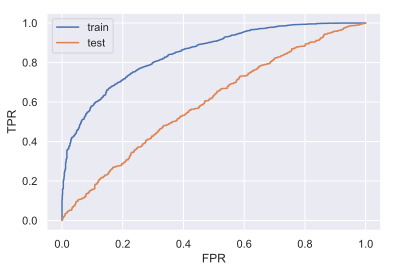

In [388]:
y_pred_clf_test1 = clf.predict_proba(X_test)[:, 1]
y_pred_clf_train1 = clf.predict_proba(X_train)[:, 1]

print('Train:')
calc_auc(y_train, y_pred_clf_train1, 'train')
print('Test:')
calc_auc(y_test, y_pred_clf_test1, 'test')
plt.legend();

In [403]:
from sklearn.metrics import precision_recall_curve, classification_report
report = classification_report(y_test, clf.predict(X_test))
print(report)

             precision    recall  f1-score   support

          0       0.51      0.14      0.22       509
          1       0.68      0.93      0.78       991

avg / total       0.62      0.66      0.59      1500



/anaconda3/lib/python3.6/site-packages/sklearn/preprocessing/label.py:151: DeprecationWarning: The truth value of an empty array is ambiguous. Returning False, but in future this will result in an error. Use `array.size > 0` to check that an array is not empty.
  if diff:


### So, about the half of samples we predict incorrect.

/anaconda3/lib/python3.6/site-packages/sklearn/preprocessing/label.py:151: DeprecationWarning: The truth value of an empty array is ambiguous. Returning False, but in future this will result in an error. Use `array.size > 0` to check that an array is not empty.
  if diff:


Confusion matrix, without normalization
[[ 71 438]
 [ 68 923]]


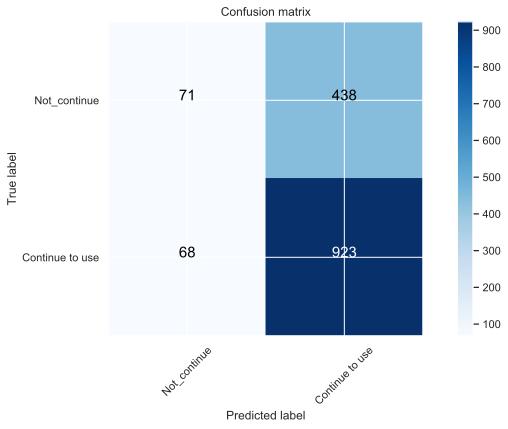

In [393]:
import itertools
cnf_matrix = confusion_matrix(y_test, clf.predict(X_test))
plt.figure(figsize=(10, 6))
plot_confusion_matrix(cnf_matrix, classes=['Not_continue', 'Continue to use'],
                      title='Confusion matrix')
plt.savefig("conf_matrix.png")
plt.show()

## Conclusion


Best model was Catboost

We made lots of feature engeneering and data preprocessing, but we can't predict thouse client who will not use our card.
For further we have to create more features: 
1. To combine numbers into groups
2. Cout WOE (Weight of Evidence on this groups
3. Make Time series of transactions for each client
4. Also 5000 of clients is not representive sample